To start with, I have taken ideas from the following code esp. to see how GCN works. Although, it does not use any CNN. 

Node classification with Graph Convolutional Network (GCN). https://stellargraph.readthedocs.io/en/stable/demos/node-classification/gcn-node-classification.html 

In [1]:
# import libraries

import os
import pandas as pd

In [2]:
# Import Libraries for Graph, GNN, and GCN

import stellargraph as sg
from stellargraph import StellarGraph

from stellargraph.mapper import FullBatchNodeGenerator
from stellargraph.layer import GCN

In [3]:
# Machine Learnig related library Imports

from tensorflow.keras import layers, optimizers, losses, metrics, Model
from sklearn import preprocessing, model_selection
from IPython.display import display, HTML
import matplotlib.pyplot as plt
%matplotlib inline


In [4]:
data = pd.read_csv('D:/paper/onging/data/bank/bankclose.csv',index_col=0)
data

,PAB,SPDB,HXB,CMBC,CMB,CIB,ABC,BOCOM,ICBC,PSBC,CEB,CZB,CCB,BOC,ECITIC
Date,,,,,,,,,,,,,,,
2018/1/2,13.70,12.72,9.11,8.52,29.62,17.24,3.85,6.28,6.18,NaN,4.08,NaN,7.79,3.98,6.32
2018/1/3,13.33,12.66,9.13,8.58,29.97,17.20,3.88,6.30,6.16,NaN,4.11,NaN,7.75,4.00,6.37
2018/1/4,13.25,12.66,9.15,8.54,29.65,17.19,3.87,6.29,6.07,NaN,4.10,NaN,7.61,4.00,6.39
2018/1/5,13.30,12.69,9.16,8.60,30.10,17.20,3.87,6.28,6.08,NaN,4.12,NaN,7.68,3.98,6.44
2018/1/8,12.96,12.68,9.19,8.72,29.47,17.22,3.86,6.31,6.07,NaN,4.13,NaN,7.59,4.01,6.54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022/12/26,12.77,7.10,5.12,3.40,35.95,17.16,2.85,4.65,4.26,4.42,2.99,2.91,5.50,3.11,4.83
2022/12/27,13.11,7.22,5.18,3.43,36.67,17.43,2.89,4.71,4.30,4.53,3.06,2.94,5.58,3.15,4.90
2022/12/28,13.14,7.30,5.18,3.43,37.33,17.61,2.90,4.75,4.32,4.60,3.06,2.95,5.61,3.16,4.98


In [5]:
drop_rows_with_na = 1

In [6]:
data.shape

(1215, 15)

In [7]:
# df_s_transpose.index = df_s_transpose['Date']
#df_s_transpose.index = df_s_transpose.index.astype('datetime64[ns]')

# Note: the above data has null and missing values. That will be addressed.

In [8]:
# Experiment find correlations
# Ref: https://towardsdatascience.com/time-series-and-correlations-with-stock-market-data-using-python-e66774e3a16f

In [9]:
df_s_transpose = data.fillna(0)

In [10]:
df_s_transpose

,PAB,SPDB,HXB,CMBC,CMB,CIB,ABC,BOCOM,ICBC,PSBC,CEB,CZB,CCB,BOC,ECITIC
Date,,,,,,,,,,,,,,,
2018/1/2,13.70,12.72,9.11,8.52,29.62,17.24,3.85,6.28,6.18,0.00,4.08,0.00,7.79,3.98,6.32
2018/1/3,13.33,12.66,9.13,8.58,29.97,17.20,3.88,6.30,6.16,0.00,4.11,0.00,7.75,4.00,6.37
2018/1/4,13.25,12.66,9.15,8.54,29.65,17.19,3.87,6.29,6.07,0.00,4.10,0.00,7.61,4.00,6.39
2018/1/5,13.30,12.69,9.16,8.60,30.10,17.20,3.87,6.28,6.08,0.00,4.12,0.00,7.68,3.98,6.44
2018/1/8,12.96,12.68,9.19,8.72,29.47,17.22,3.86,6.31,6.07,0.00,4.13,0.00,7.59,4.01,6.54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022/12/26,12.77,7.10,5.12,3.40,35.95,17.16,2.85,4.65,4.26,4.42,2.99,2.91,5.50,3.11,4.83
2022/12/27,13.11,7.22,5.18,3.43,36.67,17.43,2.89,4.71,4.30,4.53,3.06,2.94,5.58,3.15,4.90
2022/12/28,13.14,7.30,5.18,3.43,37.33,17.61,2.90,4.75,4.32,4.60,3.06,2.95,5.61,3.16,4.98


# Pearson Correlation Coefficient

In [11]:
df_s_transpose_pearson = df_s_transpose.corr()
df_s_transpose_pearson

,PAB,SPDB,HXB,CMBC,CMB,CIB,ABC,BOCOM,ICBC,PSBC,CEB,CZB,CCB,BOC,ECITIC
PAB,1.000000,-0.011124,-0.359457,-0.348780,0.928328,0.829095,-0.359065,-0.542445,-0.170257,0.620060,0.134224,0.617748,-0.032845,-0.441805,-0.323786
SPDB,-0.011124,1.000000,0.866873,0.863407,-0.227161,-0.005385,0.868233,0.715848,0.905629,-0.544724,0.919716,-0.431709,0.877382,0.815793,0.844455
HXB,-0.359457,0.866873,1.000000,0.960711,-0.511718,-0.247009,0.970067,0.918190,0.943277,-0.786396,0.796201,-0.715044,0.892905,0.945285,0.961585
CMBC,-0.348780,0.863407,0.960711,1.000000,-0.522665,-0.288067,0.946107,0.845842,0.929752,-0.694094,0.803007,-0.598983,0.872726,0.928888,0.931929
CMB,0.928328,-0.227161,-0.511718,-0.522665,1.000000,0.811346,-0.514857,-0.626905,-0.344299,0.688693,-0.090439,0.634768,-0.206617,-0.580731,-0.493881
CIB,0.829095,-0.005385,-0.247009,-0.288067,0.811346,1.000000,-0.226572,-0.314790,-0.050163,0.479700,0.138282,0.418022,0.109920,-0.267328,-0.180623
ABC,-0.359065,0.868233,0.970067,0.946107,-0.514857,-0.226572,1.000000,0.916335,0.961349,-0.731940,0.801522,-0.656759,0.911191,0.964603,0.948285
BOCOM,-0.542445,0.715848,0.918190,0.845842,-0.626905,-0.314790,0.916335,1.000000,0.850517,-0.831311,0.600592,-0.804141,0.786651,0.946321,0.902137
ICBC,-0.170257,0.905629,0.943277,0.929752,-0.344299,-0.050163,0.961349,0.850517,1.000000,-0.641047,0.854575,-0.565347,0.973207,0.931624,0.938937
PSBC,0.620060,-0.544724,-0.786396,-0.694094,0.688693,0.479700,-0.731940,-0.831311,-0.641047,1.000000,-0.418785,0.955125,-0.580943,-0.739047,-0.746073


# Pearson Correlation Coefficient based Adjacency Graph Matrix

In [12]:
df_s_transpose_pearson[df_s_transpose_pearson >= 0.5] = 1
df_s_transpose_pearson[df_s_transpose_pearson < 0.5] = 0
df_s_transpose_pearson

,PAB,SPDB,HXB,CMBC,CMB,CIB,ABC,BOCOM,ICBC,PSBC,CEB,CZB,CCB,BOC,ECITIC
PAB,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
SPDB,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0
HXB,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0
CMBC,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0
CMB,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
CIB,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ABC,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0
BOCOM,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0
ICBC,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0
PSBC,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


# Spearman Correlation Coefficient 

In [13]:
df_s_transpose_spearman = df_s_transpose.corr(method='spearman')
df_s_transpose_spearman

,PAB,SPDB,HXB,CMBC,CMB,CIB,ABC,BOCOM,ICBC,PSBC,CEB,CZB,CCB,BOC,ECITIC
PAB,1.000000,-0.072376,-0.374329,-0.365452,0.947063,0.822216,-0.392097,-0.567642,-0.229705,0.699772,0.099464,0.657092,-0.077269,-0.439288,-0.344144
SPDB,-0.072376,1.000000,0.879015,0.891656,-0.249702,-0.017282,0.876300,0.726991,0.921363,-0.390588,0.863605,-0.207629,0.897132,0.856045,0.868462
HXB,-0.374329,0.879015,1.000000,0.971597,-0.515937,-0.257126,0.969050,0.869929,0.943907,-0.592735,0.793000,-0.455295,0.886023,0.930702,0.951652
CMBC,-0.365452,0.891656,0.971597,1.000000,-0.513912,-0.282545,0.958752,0.845079,0.936673,-0.583428,0.792721,-0.393549,0.861409,0.931871,0.939082
CMB,0.947063,-0.249702,-0.515937,-0.513912,1.000000,0.833174,-0.524016,-0.627161,-0.381494,0.752862,-0.088798,0.628877,-0.226161,-0.554106,-0.485307
CIB,0.822216,-0.017282,-0.257126,-0.282545,0.833174,1.000000,-0.237418,-0.294096,-0.076550,0.593796,0.142747,0.358604,0.087725,-0.246678,-0.185630
ABC,-0.392097,0.876300,0.969050,0.958752,-0.524016,-0.237418,1.000000,0.899018,0.957881,-0.559254,0.782519,-0.430710,0.892844,0.959257,0.945675
BOCOM,-0.567642,0.726991,0.869929,0.845079,-0.627161,-0.294096,0.899018,1.000000,0.841417,-0.617841,0.546849,-0.618754,0.751228,0.934691,0.861924
ICBC,-0.229705,0.921363,0.943907,0.936673,-0.381494,-0.076550,0.957881,0.841417,1.000000,-0.481000,0.841425,-0.367689,0.962041,0.928537,0.952599
PSBC,0.699772,-0.390588,-0.592735,-0.583428,0.752862,0.593796,-0.559254,-0.617841,-0.481000,1.000000,-0.263300,0.803141,-0.385768,-0.575127,-0.577484


# Spearman Correlation Coefficient based Adjacency Graph Matrix

# Find Kendall Correlation Coefficient

In [14]:
df_s_transpose_kendall = df_s_transpose.corr(method='kendall')
df_s_transpose_kendall

,PAB,SPDB,HXB,CMBC,CMB,CIB,ABC,BOCOM,ICBC,PSBC,CEB,CZB,CCB,BOC,ECITIC
PAB,1.000000,0.025042,-0.200365,-0.206357,0.803294,0.638060,-0.232030,-0.359386,-0.121168,0.524801,0.097320,0.492573,-0.030493,-0.278970,-0.200353
SPDB,0.025042,1.000000,0.717950,0.741456,-0.104333,0.045914,0.695918,0.521701,0.764278,-0.250137,0.716081,-0.035257,0.723086,0.654675,0.684927
HXB,-0.200365,0.717950,1.000000,0.862551,-0.311465,-0.130001,0.855666,0.701441,0.802657,-0.370287,0.633489,-0.167650,0.723241,0.783496,0.809739
CMBC,-0.206357,0.741456,0.862551,1.000000,-0.318639,-0.143980,0.828868,0.655874,0.791752,-0.388301,0.630413,-0.118021,0.703520,0.785489,0.785389
CMB,0.803294,-0.104333,-0.311465,-0.318639,1.000000,0.647940,-0.335493,-0.413995,-0.222014,0.571163,-0.016253,0.450324,-0.129290,-0.369410,-0.307584
CIB,0.638060,0.045914,-0.130001,-0.143980,0.647940,1.000000,-0.113620,-0.179388,-0.017309,0.440942,0.122469,0.275173,0.079254,-0.129933,-0.097300
ABC,-0.232030,0.695918,0.855666,0.828868,-0.335493,-0.113620,1.000000,0.734245,0.835354,-0.350929,0.598513,-0.198628,0.745126,0.835208,0.806544
BOCOM,-0.359386,0.521701,0.701441,0.655874,-0.413995,-0.179388,0.734245,1.000000,0.646972,-0.395482,0.420113,-0.400717,0.577126,0.791881,0.675189
ICBC,-0.121168,0.764278,0.802657,0.791752,-0.222014,-0.017309,0.835354,0.646972,1.000000,-0.288873,0.670478,-0.164880,0.847146,0.770879,0.815424
PSBC,0.524801,-0.250137,-0.370287,-0.388301,0.571163,0.440942,-0.350929,-0.395482,-0.288873,1.000000,-0.168924,0.629788,-0.230166,-0.375466,-0.377599


In [15]:
df_s_transpose_kendall.shape

(15, 15)

# Kendall Correlation Coefficient based Adjacency Graph Matrix

Create and visualize the Graphs

In [16]:
import networkx as nx
Graph_pearson = nx.Graph(df_s_transpose_pearson)

In [17]:
Graph_spearman = nx.Graph(df_s_transpose_spearman)
Graph_kendall = nx.Graph(df_s_transpose_kendall)

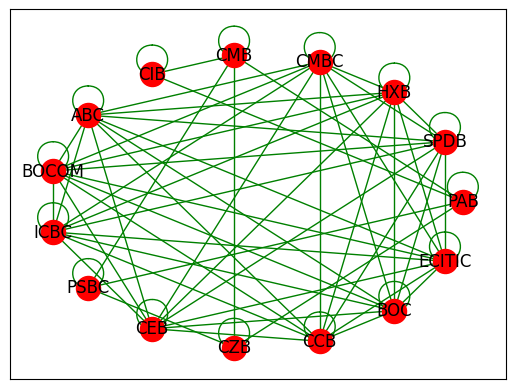

In [18]:
nx.draw_networkx(Graph_pearson, pos=nx.circular_layout(Graph_pearson), node_color='r', edge_color='g')

In [19]:
Graph_pearson

In [20]:
import numpy as np

In [58]:
np.save("D:/paper/onging/bankgraph/df_s_transpose_spearman.npy",df_s_transpose_spearman)

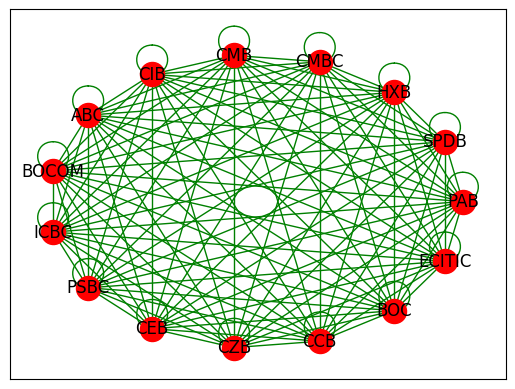

In [21]:
nx.draw_networkx(Graph_spearman, pos=nx.circular_layout(Graph_spearman), node_color='r', edge_color='g')

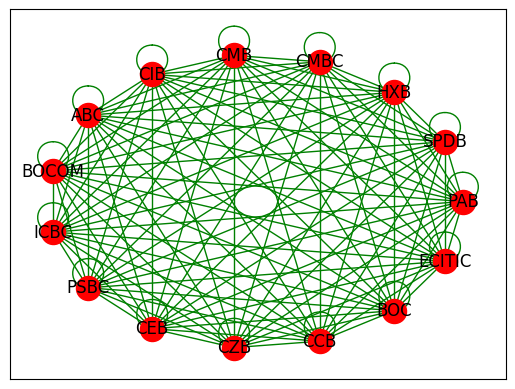

In [22]:
nx.draw_networkx(Graph_kendall, pos=nx.circular_layout(Graph_kendall), node_color='r', edge_color='g')

# Create GCN layer. Pearson

# Find all stocks = nodes

In [23]:
# improvement: make sure only stocks/nodes that are in the graph are taken
all_stock_nodes = df_s_transpose_pearson.index.to_list()
all_stock_nodes

['PAB',
 'SPDB',
 'HXB',
 'CMBC',
 'CMB',
 'CIB',
 'ABC',
 'BOCOM',
 'ICBC',
 'PSBC',
 'CEB',
 'CZB',
 'CCB',
 'BOC',
 'ECITIC']

# Find all edges between nodes

In [24]:
source = [];
target = [];
edge_feature = [];

for aStock in all_stock_nodes:
    for anotherStock in all_stock_nodes:
        if df_s_transpose_pearson[aStock][anotherStock] > 0:
            #print(df_s_transpose_pearson[aStock][anotherStock])
            source.append(aStock)
            target.append(anotherStock)
            edge_feature.append(1)
            
source, target, edge_feature            

(['PAB',
  'PAB',
  'PAB',
  'PAB',
  'PAB',
  'SPDB',
  'SPDB',
  'SPDB',
  'SPDB',
  'SPDB',
  'SPDB',
  'SPDB',
  'SPDB',
  'SPDB',
  'SPDB',
  'HXB',
  'HXB',
  'HXB',
  'HXB',
  'HXB',
  'HXB',
  'HXB',
  'HXB',
  'HXB',
  'HXB',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMB',
  'CMB',
  'CMB',
  'CMB',
  'CMB',
  'CIB',
  'CIB',
  'CIB',
  'ABC',
  'ABC',
  'ABC',
  'ABC',
  'ABC',
  'ABC',
  'ABC',
  'ABC',
  'ABC',
  'ABC',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'ICBC',
  'ICBC',
  'ICBC',
  'ICBC',
  'ICBC',
  'ICBC',
  'ICBC',
  'ICBC',
  'ICBC',
  'ICBC',
  'PSBC',
  'PSBC',
  'PSBC',
  'PSBC',
  'CEB',
  'CEB',
  'CEB',
  'CEB',
  'CEB',
  'CEB',
  'CEB',
  'CEB',
  'CEB',
  'CEB',
  'CZB',
  'CZB',
  'CZB',
  'CZB',
  'CCB',
  'CCB',
  'CCB',
  'CCB',
  'CCB',
  'CCB',
  'CCB',
  'CCB',
  'CCB',
  'CCB',
  'BOC',
  'BOC',
  'BOC',
  'BOC',
 

In [25]:
# https://stellargraph.readthedocs.io/en/stable/demos/basics/loading-pandas.html
pearson_edges = pd.DataFrame(
    {"source": source, "target": target}
)

pearson_edges_data = pd.DataFrame(
    {"source": source, "target": target, "edge_feature": edge_feature}
)


pearson_edges[:10]

,source,target
0,PAB,PAB
1,PAB,CMB
2,PAB,CIB
3,PAB,PSBC
4,PAB,CZB
5,SPDB,SPDB
6,SPDB,HXB
7,SPDB,CMBC
8,SPDB,ABC
9,SPDB,BOCOM


In [31]:
# Graph with No Feature Data, No node data, only edges

pearson_graph = StellarGraph(edges = pearson_edges, node_type_default="corner", edge_type_default="line")
#pearson_graph = StellarGraph(nodes = all_stock_nodes, edges = pearson_edges)
# graph = sg.StellarGraph(all_stock_nodes, square_edges)
print(pearson_graph.info())

In [32]:
# Trying to have the time series data as part of the nodes

In [26]:
print(df_s_transpose_pearson.info())

<class 'pandas.core.frame.DataFrame'>
Index: 15 entries, PAB to ECITIC
Data columns (total 15 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   PAB     15 non-null     float64
 1   SPDB    15 non-null     float64
 2   HXB     15 non-null     float64
 3   CMBC    15 non-null     float64
 4   CMB     15 non-null     float64
 5   CIB     15 non-null     float64
 6   ABC     15 non-null     float64
 7   BOCOM   15 non-null     float64
 8   ICBC    15 non-null     float64
 9   PSBC    15 non-null     float64
 10  CEB     15 non-null     float64
 11  CZB     15 non-null     float64
 12  CCB     15 non-null     float64
 13  BOC     15 non-null     float64
 14  ECITIC  15 non-null     float64
dtypes: float64(15)
memory usage: 2.4+ KB
None


In [27]:
df_s_transpose

,PAB,SPDB,HXB,CMBC,CMB,CIB,ABC,BOCOM,ICBC,PSBC,CEB,CZB,CCB,BOC,ECITIC
Date,,,,,,,,,,,,,,,
2018/1/2,13.70,12.72,9.11,8.52,29.62,17.24,3.85,6.28,6.18,0.00,4.08,0.00,7.79,3.98,6.32
2018/1/3,13.33,12.66,9.13,8.58,29.97,17.20,3.88,6.30,6.16,0.00,4.11,0.00,7.75,4.00,6.37
2018/1/4,13.25,12.66,9.15,8.54,29.65,17.19,3.87,6.29,6.07,0.00,4.10,0.00,7.61,4.00,6.39
2018/1/5,13.30,12.69,9.16,8.60,30.10,17.20,3.87,6.28,6.08,0.00,4.12,0.00,7.68,3.98,6.44
2018/1/8,12.96,12.68,9.19,8.72,29.47,17.22,3.86,6.31,6.07,0.00,4.13,0.00,7.59,4.01,6.54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022/12/26,12.77,7.10,5.12,3.40,35.95,17.16,2.85,4.65,4.26,4.42,2.99,2.91,5.50,3.11,4.83
2022/12/27,13.11,7.22,5.18,3.43,36.67,17.43,2.89,4.71,4.30,4.53,3.06,2.94,5.58,3.15,4.90
2022/12/28,13.14,7.30,5.18,3.43,37.33,17.61,2.90,4.75,4.32,4.60,3.06,2.95,5.61,3.16,4.98


# Structure the Feature Matrix so that it can be passed to the GCN

In [29]:
#df_s_transpose_feature = df_s_transpose.reset_index(drop = True, inplace=False)
df_s_transpose_feature =  df_s_transpose.values.tolist()
# print(df_s_transpose_feature.values.tolist())
df_s_transpose_feature[::1]

[[13.7,
  12.72,
  9.11,
  8.52,
  29.62,
  17.24,
  3.85,
  6.28,
  6.18,
  0.0,
  4.08,
  0.0,
  7.79,
  3.98,
  6.32],
 [13.33,
  12.66,
  9.13,
  8.58,
  29.97,
  17.2,
  3.88,
  6.3,
  6.16,
  0.0,
  4.11,
  0.0,
  7.75,
  4.0,
  6.37],
 [13.25,
  12.66,
  9.15,
  8.54,
  29.65,
  17.19,
  3.87,
  6.29,
  6.07,
  0.0,
  4.1,
  0.0,
  7.61,
  4.0,
  6.39],
 [13.3,
  12.69,
  9.16,
  8.6,
  30.1,
  17.2,
  3.87,
  6.28,
  6.08,
  0.0,
  4.12,
  0.0,
  7.68,
  3.98,
  6.44],
 [12.96,
  12.68,
  9.19,
  8.72,
  29.47,
  17.22,
  3.86,
  6.31,
  6.07,
  0.0,
  4.13,
  0.0,
  7.59,
  4.01,
  6.54],
 [13.08,
  12.7,
  9.19,
  8.68,
  29.77,
  17.18,
  3.83,
  6.28,
  6.09,
  0.0,
  4.1,
  0.0,
  7.56,
  3.96,
  6.48],
 [13.47,
  13.02,
  9.35,
  8.82,
  30.53,
  18.18,
  3.91,
  6.32,
  6.16,
  0.0,
  4.13,
  0.0,
  7.78,
  4.03,
  6.6],
 [13.4,
  12.94,
  9.29,
  8.8,
  30.92,
  18.03,
  3.99,
  6.35,
  6.21,
  0.0,
  4.15,
  0.0,
  7.87,
  4.09,
  6.72],
 [13.55,
  12.91,
  9.36,
  8.8

In [38]:
node_Data = [];
for x in all_stock_nodes:
    node_Data.append( df_s_transpose_feature[x].values)
    
    
node_Data    

TypeError: list indices must be integers or slices, not str

In [54]:
pearson_graph_node_data = pd.DataFrame(node_Data, index = all_stock_nodes)

pearson_graph_node_data

,0,1,2,3,4,5,6,7,8,9,...,2473,2474,2475,2476,2477,2478,2479,2480,2481,2482
WY,20.883371,20.438263,21.654745,20.832233,19.546804,19.692883,20.427731,21.428579,21.841364,20.908264,...,31.038254,31.585228,32.529999,38.842178,38.972717,37.633583,34.238174,36.493679,34.369823,29.228270
WYNN,103.048119,95.828918,101.271027,111.982628,106.370384,113.806229,133.505219,139.868958,101.328606,112.311447,...,78.199997,80.290001,83.660004,85.800003,71.500000,58.560001,54.730000,68.739998,64.510002,58.709999
XEL,20.478704,20.990484,21.830513,23.203228,20.907310,22.606117,20.919912,21.770561,21.882168,23.136805,...,69.389999,68.849998,70.220001,67.188744,73.714508,72.550545,69.048271,75.466278,76.906860,57.939999
XLEFF,0.058500,0.058500,0.096000,0.087000,0.087000,0.087000,0.087000,0.087000,0.096000,0.087000,...,0.175400,0.175400,0.165000,0.197200,0.230350,0.186830,0.192300,0.179370,0.178000,0.165000
XOM,58.954189,58.928879,59.811855,57.663715,59.913769,61.526085,57.455147,60.007206,59.686665,58.401745,...,109.809998,110.540001,111.339996,68.425552,83.246559,84.787003,83.018562,93.249321,96.830490,97.643944
XYL,24.504324,24.147791,23.936962,24.156570,24.386118,22.216503,25.022806,29.558672,23.910618,24.103863,...,109.610001,109.879997,112.349998,114.688019,84.037300,81.997032,76.324005,102.766029,97.340027,86.987679
YUM,39.336575,38.907013,42.462990,40.536289,42.107372,44.518383,43.120792,41.467388,41.854408,40.824135,...,126.449997,126.040001,128.660004,126.714371,118.175095,108.929268,114.738968,117.047028,116.725037,105.058510
ZBH,65.839821,67.201973,67.512596,67.665359,67.576027,76.108650,74.430153,79.379471,67.692314,68.006851,...,117.669998,119.000000,120.099998,121.143295,126.072327,112.593025,102.800041,116.958374,119.003792,107.059998
ZION,20.096922,20.197556,20.819284,20.315172,24.694487,25.367598,23.557787,23.945360,20.567228,20.710051,...,50.230000,51.029999,51.820000,68.328407,61.841976,52.314281,49.448040,57.347908,58.146046,48.048351
ZTS,28.952980,32.304829,30.428169,31.237307,28.636538,28.276628,29.795467,29.912426,30.390823,31.134403,...,148.130005,147.850006,154.139999,211.260025,186.840927,162.436111,173.123749,175.297516,165.997284,145.550735


# Graph with feature as part of Nodes

In [37]:
pearson_graph_with_node_features = StellarGraph(pearson_graph_node_data, edges = pearson_edges, node_type_default="corner", edge_type_default="line")
print(pearson_graph_with_node_features.info())


StellarGraph: Undirected multigraph
 Nodes: 10, Edges: 64

 Node types:
  corner: [10]
    Features: float32 vector, length 2483
    Edge types: corner-line->corner

 Edge types:
    corner-line->corner: [64]
        Weights: all 1 (default)
        Features: none


In [38]:
# Generator
generator = FullBatchNodeGenerator(pearson_graph_with_node_features, method = "gcn")

Using GCN (local pooling) filters...


No need for this block

Graph with feature as part of both Nodes and edges
although Edge data is not required


pearson_graph_with_edge_features = StellarGraph(pearson_graph_node_data, edges = pearson_edges, node_type_default="corner", edge_type_default="line")
print(pearson_graph_with_edge_features.info())
generator = FullBatchNodeGenerator(pearson_graph_with_edge_features, method = "gcn")

In [39]:
# Train Test Split

In [40]:
train_subjects, test_subjects = model_selection.train_test_split(
    pearson_graph_node_data #, train_size = 6, test_size = 4
)
# , train_size=6, test_size=None, stratify=pearson_graph_node_data

val_subjects, test_subjects_ = model_selection.train_test_split(
    test_subjects #, test_size = 2
)

#, train_size=500, test_size=None, stratify=test_subjects

#val_subjects, test_subjects = model_selection.train_test_split(
#    test_subjects, train_size=500, test_size=None, stratify=test_subjects
#)

train_subjects.shape, test_subjects.shape, val_subjects.shape, test_subjects_.shape

((7, 2483), (3, 2483), (2, 2483), (1, 2483))

In [41]:
pearson_graph_node_data

,0,1,2,3,4,5,6,7,8,9,...,2473,2474,2475,2476,2477,2478,2479,2480,2481,2482
WY,20.883371,20.438263,21.654745,20.832233,19.546804,19.692883,20.427731,21.428579,21.841364,20.908264,...,31.038254,31.585228,32.529999,38.842178,38.972717,37.633583,34.238174,36.493679,34.369823,29.228270
WYNN,103.048119,95.828918,101.271027,111.982628,106.370384,113.806229,133.505219,139.868958,101.328606,112.311447,...,78.199997,80.290001,83.660004,85.800003,71.500000,58.560001,54.730000,68.739998,64.510002,58.709999
XEL,20.478704,20.990484,21.830513,23.203228,20.907310,22.606117,20.919912,21.770561,21.882168,23.136805,...,69.389999,68.849998,70.220001,67.188744,73.714508,72.550545,69.048271,75.466278,76.906860,57.939999
XLEFF,0.058500,0.058500,0.096000,0.087000,0.087000,0.087000,0.087000,0.087000,0.096000,0.087000,...,0.175400,0.175400,0.165000,0.197200,0.230350,0.186830,0.192300,0.179370,0.178000,0.165000
XOM,58.954189,58.928879,59.811855,57.663715,59.913769,61.526085,57.455147,60.007206,59.686665,58.401745,...,109.809998,110.540001,111.339996,68.425552,83.246559,84.787003,83.018562,93.249321,96.830490,97.643944
XYL,24.504324,24.147791,23.936962,24.156570,24.386118,22.216503,25.022806,29.558672,23.910618,24.103863,...,109.610001,109.879997,112.349998,114.688019,84.037300,81.997032,76.324005,102.766029,97.340027,86.987679
YUM,39.336575,38.907013,42.462990,40.536289,42.107372,44.518383,43.120792,41.467388,41.854408,40.824135,...,126.449997,126.040001,128.660004,126.714371,118.175095,108.929268,114.738968,117.047028,116.725037,105.058510
ZBH,65.839821,67.201973,67.512596,67.665359,67.576027,76.108650,74.430153,79.379471,67.692314,68.006851,...,117.669998,119.000000,120.099998,121.143295,126.072327,112.593025,102.800041,116.958374,119.003792,107.059998
ZION,20.096922,20.197556,20.819284,20.315172,24.694487,25.367598,23.557787,23.945360,20.567228,20.710051,...,50.230000,51.029999,51.820000,68.328407,61.841976,52.314281,49.448040,57.347908,58.146046,48.048351
ZTS,28.952980,32.304829,30.428169,31.237307,28.636538,28.276628,29.795467,29.912426,30.390823,31.134403,...,148.130005,147.850006,154.139999,211.260025,186.840927,162.436111,173.123749,175.297516,165.997284,145.550735


In [42]:
train_targets = train_subjects; 
val_targets = val_subjects; 
test_targets = test_subjects; 

In [43]:
train_gen = generator.flow(train_subjects.index, train_targets)

# This was there, but for classification, model does not match. I am changing
gcn = GCN(
    layer_sizes=[16, 16], activations=["relu", "relu"], generator=generator , dropout=0.5
)
x_inp, x_out = gcn.in_out_tensors()
predictions = layers.Dense(units=train_targets.shape[1], activation="softmax")(x_out)


In [44]:
from tensorflow.keras.layers import Dense, Conv1D, MaxPool1D, Dropout, Flatten
from tensorflow import keras

# layer_sizes = [32, 1, 32, 1, 32, 1]
# activations = ["relu", 'linear', "relu", 'linear',"relu", 'linear']

layer_sizes = [32, 32]
activations = ["relu", "relu"]

gcn = GCN(layer_sizes = layer_sizes, activations = activations, generator = generator) #, dropout = 0.5
x_inp, x_out = gcn.in_out_tensors()

#x_out = Conv1D(filters = 2, kernel_size = 2)(x_out)
#x_out = MaxPool1D(pool_size=2)(x_out)
#x_out = Conv1D(filters = 32, kernel_size = sum(layer_sizes))(x_out)
#prediction = keras.layers.Reshape((-1,))(prediction)
#x_out = keras.layers.Reshape((1,16))(x_out)
#x_out = GCN(layer_sizes = layer_sizes, activations = activations, generator = generator)(x_out) #, dropout = 0.5

# predictions = layers.Dense(units=train_targets.shape[1], activation="softmax")(x_out)
predictions = layers.Dense(units = train_targets.shape[1], activation = "linear")(x_out)
x_out, 
x_inp, x_out

([<KerasTensor: shape=(1, 10, 2483) dtype=float32 (created by layer 'input_1')>,
  <KerasTensor: shape=(1, None) dtype=int32 (created by layer 'input_2')>,
  <KerasTensor: shape=(1, None, 2) dtype=int64 (created by layer 'input_3')>,
  <KerasTensor: shape=(1, None) dtype=float32 (created by layer 'input_4')>],
 <KerasTensor: shape=(1, None, 32) dtype=float32 (created by layer 'gather_indices')>)

# Experiment with Models

In [45]:
from tensorflow.keras.layers import Dense, Conv1D, MaxPool1D, Dropout, Flatten
from tensorflow import keras

# layer_sizes = [32, 1, 32, 1, 32, 1]
# activations = ["relu", 'linear', "relu", 'linear',"relu", 'linear']

layer_sizes = [32, 32]
activations = ["relu", "relu"]

gcn = GCN(layer_sizes = layer_sizes, activations = activations, generator = generator) #, dropout = 0.5
x_inp, x_out = gcn.in_out_tensors()
xout = x_out

#x_out = Conv1D(filters = 7, kernel_size = 7)(x_out)
input_shape = (4, 10, 128)
x_out = Conv1D(32, 3, activation = 'relu', input_shape = x_out[1:] )(x_out)
#x_out = MaxPool1D(pool_size=2)(x_out)
#x_out = Conv1D(filters = 32, kernel_size = sum(layer_sizes))(x_out)
#prediction = keras.layers.Reshape((-1,))(prediction)
#x_out = keras.layers.Reshape((1,16))(x_out)

# Generator
#generator2 = FullBatchNodeGenerator(x_out, method = "gcn")
gcn2 = GCN(layer_sizes = layer_sizes, activations = activations, generator = generator)#(x_out) #, dropout = 0.5

# predictions = layers.Dense(units=train_targets.shape[1], activation="softmax")(x_out)
predictions = layers.Dense(units = train_targets.shape[1], activation = "linear")(x_out)
#x_out, 
x_inp, x_out, type(xout),  vars(gcn), 
x_out[1:]

<KerasTensor: shape=(0, None, 32) dtype=float32 (created by layer 'tf.__operators__.getitem_1')>

In [46]:
import tensorflow as tf
input_shape = (4, 10, 128)
x = tf.random.normal(input_shape)
y = keras.layers.Conv1D(32, 3, activation='relu',input_shape=input_shape[1:])(x)
#print(y.shape)

#https://keras.io/api/layers/convolution_layers/convolution1d
x_out_cnn = Conv1D(32, 3, activation='relu',input_shape=input_shape[1:])(x_out)
x, 
input_shape[1:], x_out_cnn

((10, 128),
 <KerasTensor: shape=(1, None, 32) dtype=float32 (created by layer 'conv1d_2')>)

In [47]:
# Not my code
# https://machinelearningmastery.com/how-to-develop-convolutional-neural-network-models-for-time-series-forecasting/
# univariate cnn example
from numpy import array
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Flatten
from keras.layers.convolutional import Conv1D
from keras.layers.convolutional import MaxPooling1D

# split a univariate sequence into samples
def split_sequence(sequence, n_steps):
	X, y = list(), list()
	for i in range(len(sequence)):
		# find the end of this pattern
		end_ix = i + n_steps
		# check if we are beyond the sequence
		if end_ix > len(sequence)-1:
			break
		# gather input and output parts of the pattern
		seq_x, seq_y = sequence[i:end_ix], sequence[end_ix]
		X.append(seq_x)
		y.append(seq_y)
	return array(X), array(y)

# define input sequence
raw_seq = [10, 20, 30, 40, 50, 60, 70, 80, 90]
# choose a number of time steps
n_steps = 3
# split into samples
X, y = split_sequence(raw_seq, n_steps)
# reshape from [samples, timesteps] into [samples, timesteps, features]
n_features = 1
X = X.reshape((X.shape[0], X.shape[1], n_features))
# define model
model = Sequential()
model.add(Conv1D(filters=64, kernel_size=2, activation='relu', input_shape=(n_steps, n_features)))
model.add(MaxPooling1D(pool_size=2))
model.add(Flatten())
model.add(Dense(50, activation='relu'))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')
# fit model
model.fit(X, y, epochs=1000, verbose=0)
# demonstrate prediction
x_input = array([70, 80, 90])
x_input = x_input.reshape((1, n_steps, n_features))
yhat = model.predict(x_input, verbose=0)
print(yhat)

[[100.863434]]


x_out, vars(gcn)

In [48]:
# Models

In [49]:
# loss functions: https://keras.io/api/losses/

model = Model(inputs=x_inp, outputs=predictions)
'''
model.compile(
    optimizer=optimizers.Adam(learning_rate=0.1),
    loss=losses.MeanSquaredError(),
    metrics=["acc"],
)
'''
model.compile(loss='mean_absolute_error', optimizer=optimizers.Adam(learning_rate=0.1), metrics=['mean_squared_error'])

In [50]:
len(x_inp) , predictions.shape, print(model.summary())

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_5 (InputLayer)           [(1, 10, 2483)]      0           []                               
                                                                                                  
 input_7 (InputLayer)           [(1, None, 2)]       0           []                               
                                                                                                  
 input_8 (InputLayer)           [(1, None)]          0           []                               
                                                                                                  
 dropout_2 (Dropout)            (1, 10, 2483)        0           ['input_5[0][0]']                
                                                                                              

(4, TensorShape([1, None, 2483]), None)

In [51]:
len(val_subjects)
test_subjects_ = test_subjects[:len(val_subjects)]

In [52]:
# hard coded size adjustments
test_subjects_ = test_subjects[:len(val_subjects)]

val_gen = generator.flow(val_subjects.index, test_subjects_)
#train_gen[1], val_gen[1]

train_gen[:1][:4]

In [53]:
# https://keras.io/api/callbacks/early_stopping/
from tensorflow.keras.callbacks import EarlyStopping

es_callback = EarlyStopping(monitor = "val_mean_squared_error", patience = 50, restore_best_weights = True)

data_valid = val_gen #[:1][:4];
train_gen_data = train_gen #[:1][:4];

history = model.fit( train_gen_data, epochs = 100, validation_data = data_valid, verbose = 2,    
    # shuffling = true means shuffling the whole graph
    shuffle = False, callbacks = [es_callback],
)
sg.utils.plot_history(history)

# [1]

Epoch 1/100


InvalidArgumentError: Graph execution error:

Detected at node 'gradient_tape/mean_absolute_error/sub/BroadcastGradientArgs' defined at (most recent call last):
    File "C:\Users\sayed\.conda\envs\stellargraph\lib\runpy.py", line 194, in _run_module_as_main
      return _run_code(code, main_globals, None,
    File "C:\Users\sayed\.conda\envs\stellargraph\lib\runpy.py", line 87, in _run_code
      exec(code, run_globals)
    File "C:\Users\sayed\.conda\envs\stellargraph\lib\site-packages\ipykernel_launcher.py", line 17, in <module>
      app.launch_new_instance()
    File "C:\Users\sayed\.conda\envs\stellargraph\lib\site-packages\traitlets\config\application.py", line 992, in launch_instance
      app.start()
    File "C:\Users\sayed\.conda\envs\stellargraph\lib\site-packages\ipykernel\kernelapp.py", line 711, in start
      self.io_loop.start()
    File "C:\Users\sayed\.conda\envs\stellargraph\lib\site-packages\tornado\platform\asyncio.py", line 215, in start
      self.asyncio_loop.r

In [ ]:
val_subjects, 
test_subjects

In [ ]:
test_gen = generator.flow(test_subjects.index, test_targets)
test_metrics = model.evaluate(test_gen)
print("\nTest Set Metrics:")
for name, val in zip(model.metrics_names, test_metrics):
    print("\t{}: {:0.4f}".format(name, val))
    

# Show the predicted prices by the Model

At this point, I still need to make sense of what GCN ( and CNN) combination + MLP is predicting. 
I am just displaying the output. 
It appears that price is predicted for each timestamp (day)

In [ ]:
all_nodes = pearson_graph_node_data.index;
all_gen = generator.flow(all_nodes)
all_predictions = model.predict(all_gen)

all_predictions, all_predictions.shape, pearson_graph_node_data.shape

In [ ]:
vars(all_gen)

In [ ]:
# train_gen[:1][:4]

References:



[1] Node classification with Graph Convolutional Network (GCN). https://stellargraph.readthedocs.io/en/stable/demos/node-classification/gcn-node-classification.html 


[2] Loading data into StellarGraph from Pandas. https://stellargraph.readthedocs.io/en/stable/demos/basics/loading-pandas.html

[3] Load Timeseries https://stellargraph.readthedocs.io/en/stable/demos/basics/loading-numpy.html

[4] NetworkX: https://networkx.org/documentation/stable/reference/introduction.html 

[5]  StellerGraph and Networkx https://stellargraph.readthedocs.io/en/latest/demos/basics/loading-networkx.html 

[6] Select StellerGraph Algorithm : https://stellargraph.readthedocs.io/en/stable/demos/#find-a-demo-for-an-algorithm 
[link text](https://)


Learning: 
GNN/GCN/Keras
https://www.youtube.com/watch?v=0KH95BEz370


Install StellarGraph:
https://pypi.org/project/stellargraph/#install-stellargraph-using-pypi


May want to use without Stellar
https://keras.io/examples/graph/gnn_citations/

to get feature data from pandas dataframe: 
https://stellargraph.readthedocs.io/en/stable/demos/basics/loading-pandas.html


Create graph properly:
https://stellargraph.readthedocs.io/en/stable/demos/basics/loading-pandas.html    

https://stellargraph.readthedocs.io/en/v0.11.0/api.html


Graph Regression Dataset
https://paperswithcode.com/task/graph-regression/codeless

StellerGraph Reference:
https://stellargraph.readthedocs.io/en/stable/demos/time-series/gcn-lstm-time-series.html
https://stellargraph.readthedocs.io

GRaph CNN or similar
It has multiple GCN layers and one 1d CNN + ... this idea might help
https://stellargraph.readthedocs.io/en/stable/demos/graph-classification/dgcnn-graph-classification.html?highlight=cnn

# References -- exploring ideas on the GCN-CNN
https://ieeexplore.ieee.org/document/9149910

https://antonsruberts.github.io/graph/gcn/

This may work. As Unit GCN is created also unit tcn. This may give the opportunity to customize to product the correct output
https://github.com/lshiwjx/2s-AGCN  https://paperswithcode.com/paper/non-local-graph-convolutional-networks-for

    

In [ ]:
import scipy.stats as stats
c, p = stats.pearsonr(df_s_transpose['WY'], df_s_transpose['WYNN'])
print(f"WY vs WYNN Pearson Correlation: {c}\n")